# Paper 01: Delving Deep into Rectifiers (Kaiming Initialization)
**Authors**: Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun (2015)

---

## 1. The Historical Problem (What Broke Before This?)
Before 2015, neural networks were initialized with **Xavier (Glorot) Initialization**:
$$\text{Var}[W] = \frac{2}{n_{\text{in}} + n_{\text{out}}}$$

Xavier initialization assumed linear or symmetric activations (like $\tanh$). But when networks switched to **ReLU** ($f(x) = \max(0, x)$), all negative inputs were zeroed out, **halving the variance at every single layer**:
$$\text{Var}[y_l] \approx \left(\frac{1}{2}\right) \text{Var}[y_{l-1}]$$

By layer 30, the signal variance dropped by $\left(\frac{1}{2}\right)^{30} \approx 10^{-9}$—activations collapsed to absolute zero, killing all backward gradients!

## 2. The First-Principles Solution: If You Were Inventing It
If the activation function cuts signal energy in half, the fix is intuitive: **inject twice the variance into your initial weights**:
$$\text{Var}[W] = \frac{2}{n_{\text{in}}}$$
The $2\times$ weight variance cancels out the $1/2\times$ reduction from the ReLU gate, keeping signal variance constant across 30+ deep layers!

In this exercise, you will implement Kaiming initialization from scratch in `model.py` and test it here.

---
## Setup
`%autoreload 2` ensures any edits you make in `model.py` are instantly picked up here without restarting the kernel.

In [9]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Import your functions from model.py
from model import calculate_gain, _calculate_fan, kaiming_uniform_, kaiming_normal_, init_weights, DeepMLP
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: Gain and Fan Calculations

Implement `calculate_gain` and `_calculate_fan` in `model.py`.
- `calculate_gain`: Returns scaling factor (e.g. $\sqrt{2}$ for ReLU).
- `_calculate_fan`: Computes `fan_in` and `fan_out` for Linear (`2D`) and Conv2d (`4D`) tensors.

In [10]:
print("Testing calculate_gain:")
tests.test_calculate_gain(calculate_gain)

print("\nTesting _calculate_fan:")
tests.test_calculate_fan(_calculate_fan)

Testing calculate_gain:
  [PASS] calculate_gain is correct across all activations!

Testing _calculate_fan:
  [PASS] _calculate_fan correctly handles Linear (2D) and Conv2d (4D) tensors!


True

---
## Part 2: In-Place Uniform and Normal Initialization

Implement `kaiming_uniform_` and `kaiming_normal_` in `model.py`.
- `std = gain / sqrt(fan)`
- `kaiming_normal_`: Samples $W \sim \mathcal{N}(0, \text{std}^2)$
- `kaiming_uniform_`: Samples $W \sim \mathcal{U}(-\text{bound}, \text{bound})$ where $\text{bound} = \sqrt{3} \cdot \text{std}$

In [11]:
print("Testing kaiming_uniform_:")
tests.test_kaiming_uniform(kaiming_uniform_)

print("\nTesting kaiming_normal_:")
tests.test_kaiming_normal(kaiming_normal_)

Testing kaiming_uniform_:
  [PASS] kaiming_uniform_ variance (~0.0447) and bounds match theory!

Testing kaiming_normal_:
  [PASS] kaiming_normal_ mean (-0.0000) and std (0.0447) match theory!


True

---
## Part 3: Recursive Module Weight Initialization

Implement `init_weights(module, ...)` in `model.py` to recursively initialize all `Linear` and `Conv` layers, and zero out biases.

In [13]:
print("Testing init_weights helper:")
tests.test_init_weights(init_weights)

Testing init_weights helper:
  [PASS] init_weights correctly applies initialization and zeroes biases!


True

---
## Part 4: The 30-Layer Variance Experiment!

Now see the power of your implementation firsthand!
We pass a random batch through a **30-layer deep network**:
1. Under default initialization (signal vanishes by layer 30).
2. Under your Kaiming initialization (signal stays alive all the way to layer 30!).

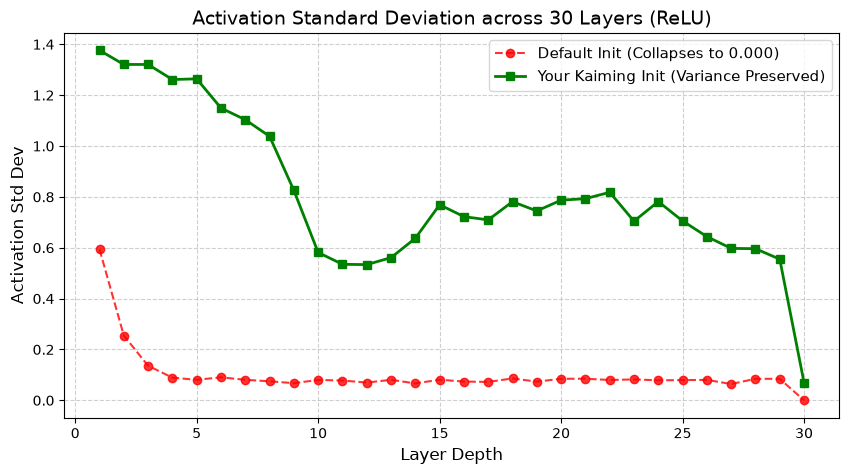

Layer 30 Std Dev -> Default: 0.00000000 vs Your Kaiming: 0.0693


In [18]:
torch.manual_seed(42)
x = torch.randn(64, 64)

# 1. Default (uninitialized) model
model_default = DeepMLP(in_dim=64, hidden_dim=64, num_layers=30)
_, stats_default = model_default.forward_with_layer_stats(x)

# 2. Your Kaiming-initialized model
model_kaiming = DeepMLP(in_dim=64, hidden_dim=64, num_layers=30)
init_weights(model_kaiming, nonlinearity="relu", distribution="normal")
_, stats_kaiming = model_kaiming.forward_with_layer_stats(x)

# Plot the layer-by-layer standard deviations
layers = list(range(1, 31))
stds_default = [s[1] for s in stats_default]
stds_kaiming = [s[1] for s in stats_kaiming]

plt.figure(figsize=(10, 5))
plt.plot(layers, stds_default, 'r--o', label='Default Init (Collapses to 0.000)', alpha=0.8)
plt.plot(layers, stds_kaiming, 'g-s', label='Your Kaiming Init (Variance Preserved)', linewidth=2)
plt.title('Activation Standard Deviation across 30 Layers (ReLU)', fontsize=14)
plt.xlabel('Layer Depth', fontsize=12)
plt.ylabel('Activation Std Dev', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

print(f"Layer 30 Std Dev -> Default: {stds_default[-1]:.8f} vs Your Kaiming: {stds_kaiming[-1]:.4f}")

---
## Part 5: Single-Batch Overfit Gate

To confirm your network learns properly with these weights, we train on a single batch for 50 steps.
The training loss must collapse towards zero.

In [15]:
torch.manual_seed(42)
model = DeepMLP(in_dim=16, hidden_dim=32, out_dim=2, num_layers=10)
init_weights(model, nonlinearity="relu", distribution="normal")

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

batch_x = torch.randn(4, 16)
batch_y = torch.randn(4, 2)

print("Training single batch for 50 steps:")
for step in range(1, 51):
    optimizer.zero_grad()
    pred = model(batch_x)
    loss = loss_fn(pred, batch_y)
    loss.backward()
    optimizer.step()
    if step == 1 or step % 10 == 0:
        print(f"  Step {step:02d} | Loss: {loss.item():.6f}")

assert loss.item() < 0.01, f"Loss did not drop below 0.01 (loss={loss.item():.4f})"
print(f"\n[PASS] Overfit gate passed! Final loss: {loss.item():.6f} (< 0.01)")

Training single batch for 50 steps:
  Step 01 | Loss: 1.701597
  Step 10 | Loss: 0.047577
  Step 20 | Loss: 0.014090
  Step 30 | Loss: 0.002900
  Step 40 | Loss: 0.001207
  Step 50 | Loss: 0.000422

[PASS] Overfit gate passed! Final loss: 0.000422 (< 0.01)
